In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from matplotlib import pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,BatchNormalization,Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [2]:
df = pd.read_csv("StudentPerformanceFactors.csv")
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [4]:
df["Teacher_Quality"] = df["Teacher_Quality"].fillna(df["Teacher_Quality"].mode()[0])
df["Parental_Education_Level"] = df["Parental_Education_Level"].fillna(df["Parental_Education_Level"].mode()[0])
df["Parental_Education_Level"] = df["Parental_Education_Level"].fillna(df["Parental_Education_Level"].mode()[0])

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
# categorical data:
label = LabelEncoder()
df["encoded_parentinvole"] = label.fit_transform(df["Parental_Involvement"])
var1 = dict(zip(df["Parental_Involvement"],df["encoded_parentinvole"]))
print(var1)

df["encoded_resources"] = label.fit_transform(df["Access_to_Resources"])
var2 = dict(zip(df["Access_to_Resources"],df["encoded_resources"]))
print(var2)

df["encoded_activities"] = label.fit_transform(df["Extracurricular_Activities"])
var3 = dict(zip(df["Extracurricular_Activities"],df["encoded_activities"]))
print(var3)

df["encoded_motivation"] = label.fit_transform(df["Motivation_Level"])
var4 = dict(zip(df["Motivation_Level"],df["encoded_motivation"]))
print(var4)

df["encoded_internet"] = label.fit_transform(df["Internet_Access"])
var5 = dict(zip(df["Internet_Access"],df["encoded_internet"]))
print(var5)

df["encoded_income"] = label.fit_transform(df["Family_Income"])
var6 = dict(zip(df["Family_Income"],df["encoded_income"]))
print(var6)

df["encoded_teacher"] = label.fit_transform(df["Teacher_Quality"])
var7 = dict(zip(df["Teacher_Quality"],df["encoded_teacher"]))
print(var7)

df["encoded_school"] = label.fit_transform(df["School_Type"])
var8 = dict(zip(df["School_Type"],df["encoded_school"]))
print(var8)

df["encoded_peer"] = label.fit_transform(df["Peer_Influence"])
var9 = dict(zip(df["Peer_Influence"],df["encoded_peer"]))
print(var9)

df["encoded_disability"] = label.fit_transform(df["Learning_Disabilities"])
var10 = dict(zip(df["Learning_Disabilities"],df["encoded_disability"]))
print(var10)


df["encoded_parent_edu"] = label.fit_transform(df["Parental_Education_Level"])
var11 = dict(zip(df["encoded_parent_edu"],df["Parental_Education_Level"]))
print(var11)

df["encoded_dist"] = label.fit_transform(df["Distance_from_Home"])
var12 = dict(zip(df["encoded_dist"],df["Distance_from_Home"]))
print(var12)

df["encoded_gender"] = label.fit_transform(df["Gender"])
var13 = dict(zip(df["encoded_gender"],df["Gender"]))
print(var13)

{'Low': 1, 'Medium': 2, 'High': 0}
{'High': 0, 'Medium': 2, 'Low': 1}
{'No': 0, 'Yes': 1}
{'Low': 1, 'Medium': 2, 'High': 0}
{'Yes': 1, 'No': 0}
{'Low': 1, 'Medium': 2, 'High': 0}
{'Medium': 2, 'High': 0, 'Low': 1}
{'Public': 1, 'Private': 0}
{'Positive': 2, 'Negative': 0, 'Neutral': 1}
{'No': 0, 'Yes': 1}
{1: 'High School', 0: 'College', 2: 'Postgraduate'}
{2: 'Near', 1: 'Moderate', 0: 'Far', 3: nan}
{1: 'Male', 0: 'Female'}


In [7]:
df.drop(columns=["Parental_Involvement","Access_to_Resources","Extracurricular_Activities","Motivation_Level","Internet_Access","Family_Income","Teacher_Quality","School_Type","Peer_Influence","Learning_Disabilities","Parental_Education_Level","Distance_from_Home","Gender"],inplace=True)
df.head()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score,encoded_parentinvole,encoded_resources,encoded_activities,encoded_motivation,encoded_internet,encoded_income,encoded_teacher,encoded_school,encoded_peer,encoded_disability,encoded_parent_edu,encoded_dist,encoded_gender
0,23,84,7,73,0,3,67,1,0,0,1,1,1,2,1,2,0,1,2,1
1,19,64,8,59,2,4,61,1,2,0,1,1,2,2,1,0,0,0,1,0
2,24,98,7,91,2,4,74,2,2,1,2,1,2,2,1,1,0,2,2,1
3,29,89,8,98,1,4,71,1,2,1,2,1,2,2,1,0,0,1,1,1
4,19,92,6,65,3,4,70,2,2,1,2,1,2,0,1,1,0,0,2,0


In [8]:
#feature selection
x = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

In [9]:
# splitting of data:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [10]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [15]:

# ann architecture:
model = Sequential()

#input layer:
model.add(Dense(512,activation="sigmoid",input_dim=19))

#hidden layer:
model.add(Dense(256,activation="relu"))

model.add(Dense(128,activation="relu"))

model.add(Dense(64,activation="relu"))

#output layer:
model.add(Dense(1,activation="linear"))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 512)            │        10,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 182,785 (714.00 KB)

 Trainable params: 182,785 (714.00 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:

#model compile:
model.compile(optimizer="adam",loss= "mae", metrics= ["r2_score"])

In [19]:
history = model.fit(x_train_scaled,y_train,batch_size= 32,epochs=50,validation_split=0.2,verbose=1)

Epoch 1/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.2215 - r2_score: 0.6466 - val_loss: 1.5078 - val_r2_score: 0.4624
Epoch 2/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.2736 - r2_score: 0.6310 - val_loss: 2.3065 - val_r2_score: 0.3244
Epoch 3/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.3220 - r2_score: 0.6250 - val_loss: 1.2843 - val_r2_score: 0.4602
Epoch 4/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.2127 - r2_score: 0.6493 - val_loss: 1.4818 - val_r2_score: 0.4140
Epoch 5/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.2100 - r2_score: 0.6494 - val_loss: 1.2301 - val_r2_score: 0.4747
Epoch 6/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.2373 - r2_score: 0.6488 - val_loss: 2.5294 - val_r2_score: 0.1447
Epoch 7/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.2288 - r2_score: 0.6437 - val_loss: 2.2330 - val_r2_score: 0.3406
Epoch 8/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.2744 - r2_score: 0.6345 - val_loss: 1.5462

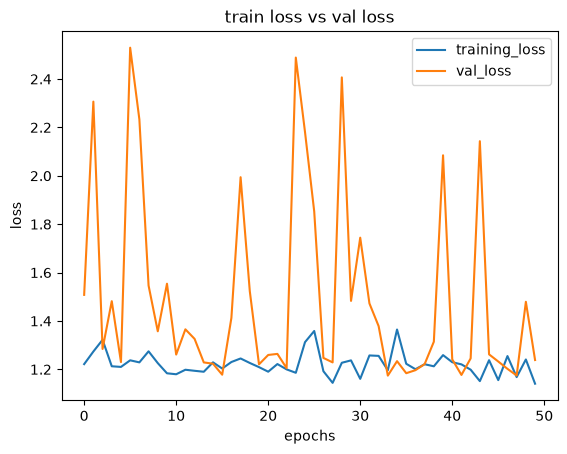

In [20]:
#plot the graphs:
plt.plot(history.history["loss"],label="training_loss")
plt.plot(history.history["val_loss"],label="val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("train loss vs val loss")
plt.legend()
plt.show()

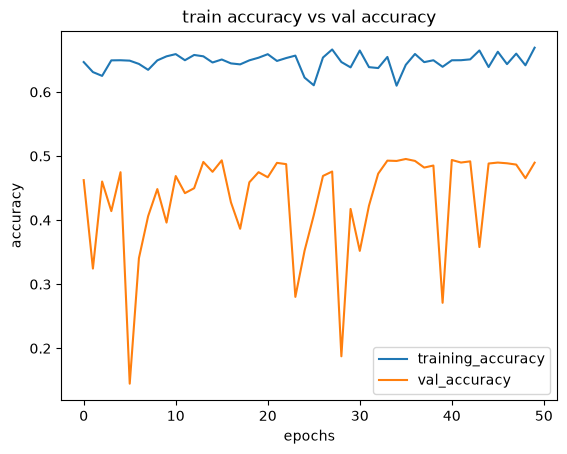

In [21]:
#plot the graphs:
plt.plot(history.history["r2_score"],label="training_accuracy")
plt.plot(history.history["val_r2_score"],label="val_accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("train accuracy vs val accuracy")
plt.legend()
plt.show()